# Bitcoin OTC: temporal rating accumulation

**Focused question:** Did positive incoming ratings become more concentrated as this observed network grew, and were already highly rated users selected more often than a simple uniform-target baseline predicts? Ratings are directed opinions. The timestamps record when ratings were added; they do not establish that an old rating remained an active relationship.

## 1. Reproduce the outputs

Download the original SNAP file as described in the repository README, then run `python scripts/temporal_analysis.py` from the repository root. This notebook reads the script outputs and exposes the definitions and caveats.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
OUT = ROOT / 'outputs' / 'temporal'
annual = pd.read_csv(OUT / 'annual_snapshots.csv')
strong = pd.read_csv(OUT / 'annual_snapshots_rating_ge5.csv')
choice = pd.read_csv(OUT / 'target_choice_by_prior_degree.csv')
by_year = pd.read_csv(OUT / 'target_choice_by_year.csv')
meta = json.loads((OUT / 'metadata.json').read_text())
display(pd.Series(meta, name='value'))

source_sha256                             6424ac981dad3a019f697fc1b9fcd85c19d8d9f0397977...
positive_ratings                                                                      32029
full_years                                                   [2011, 2012, 2013, 2014, 2015]
timestamp_ties                                                                            0
event_order                                            SNAP file order for equal timestamps
null                                      uniform eligible active target at each positiv...
limits                                    descriptive association; activity, tenure, and...
eligible_existing_target_events                                                       27133
first_time_target_events_excluded                                                      4896
insufficient_candidate_events_excluded                                                    0
expected_sum                                                                    

## 2. Evolution of observed rating concentration

At each UTC year end, keep all positive ratings observed up to that point. **Active positive users** are users who have appeared as a source or target in these retained ratings. Incoming degree counts distinct positive raters; because the source has no repeated directed pairs, it also equals the number of positive incoming rating records. The top-1% share is the fraction of all positive incoming ratings received by the highest-in-degree 1% of active users, rounding the group size upward. Gini summarizes inequality across all active users, including those with zero incoming positive ratings. We use 2011–2015 as full years; 2010 and 2016 are partial.

,rating_threshold,year_end,active_positive_users,cumulative_positive_ratings,top_1_percent_incoming_share,incoming_degree_gini,top_group_size
0,1,2011,1631,7745,0.1551,0.6115,17
1,1,2012,3116,16367,0.1991,0.6586,32
2,1,2013,4991,27505,0.2248,0.6789,50
3,1,2014,5455,31060,0.2316,0.6878,55
4,1,2015,5571,31989,0.2352,0.6911,56


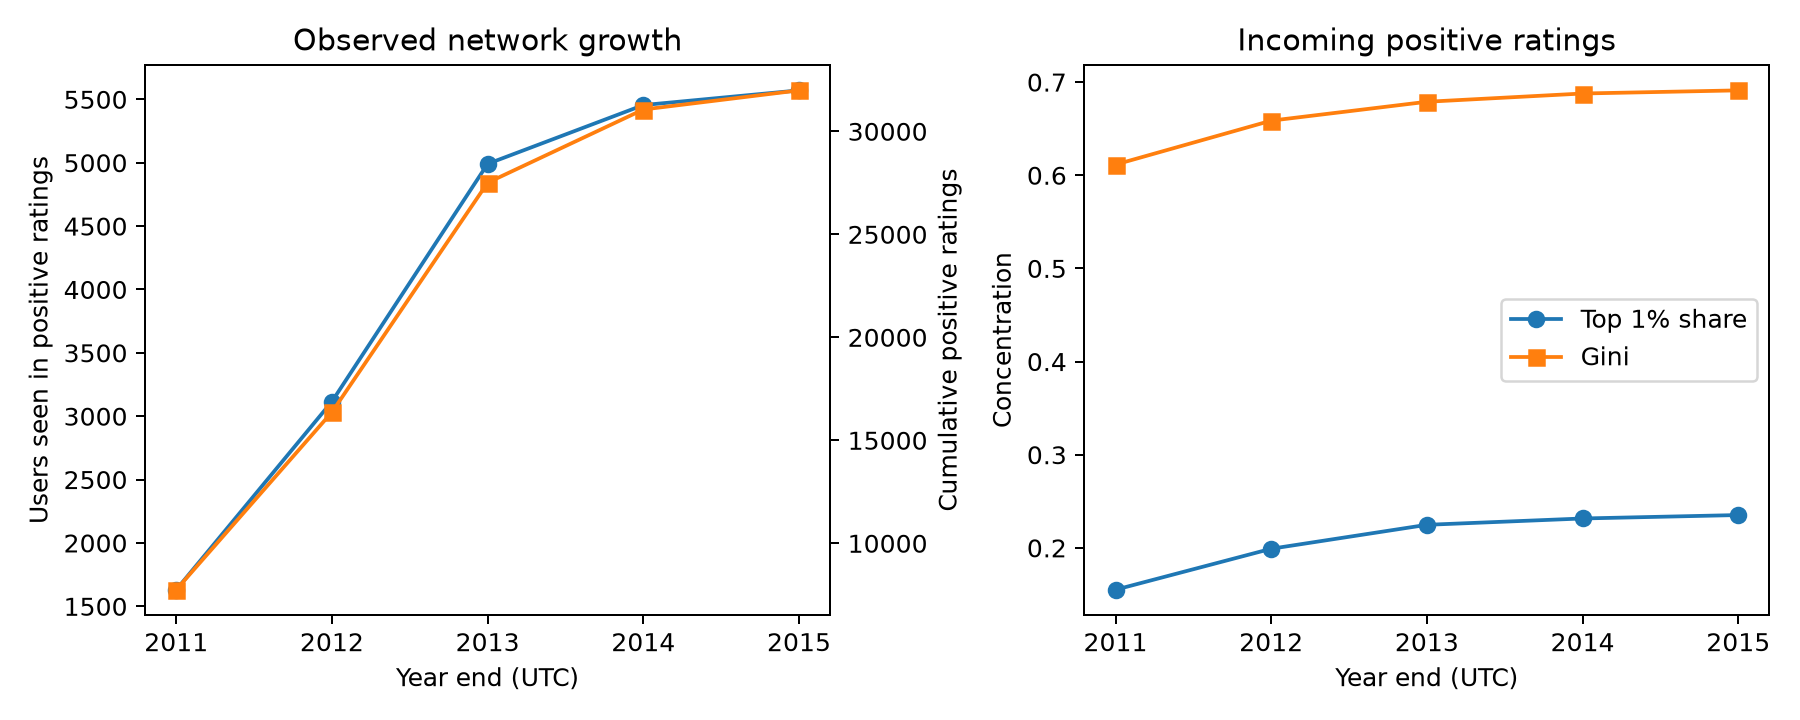

In [2]:
display(annual.round(4))
display(Image(filename=str(OUT / 'growth_and_concentration.png')))

## 3. Event-level target-choice comparison

Before each positive rating, the candidate set contains users seen in earlier positive ratings, excluding the rater and users the rater previously rated positively. If the actual target is new, that event is excluded from this particular comparison. For each eligible event, we calculate the probability that a uniformly drawn eligible target belongs to each **prior positive in-degree** bin. Summing those probabilities gives the expected count for that bin. The observed/expected ratio is one under this simple null. This conditions on the changing pool of observed users and past positive ratings from the same source, but **does not control for user activity, tenure, trading volume, or platform membership**. A high ratio is an association, not proof of preferential attachment.

,prior_positive_in_degree,observed_target_events,uniform_null_expected_events,observed_over_expected
0,0,601,341.660,1.759
1,1,3090,11200.671,0.276
2,2-3,3717,7671.863,0.484
3,4-7,4145,4133.610,1.003
4,8-15,4223,2282.943,1.850
5,16-31,4001,922.895,4.335
6,32+,7356,579.358,12.697


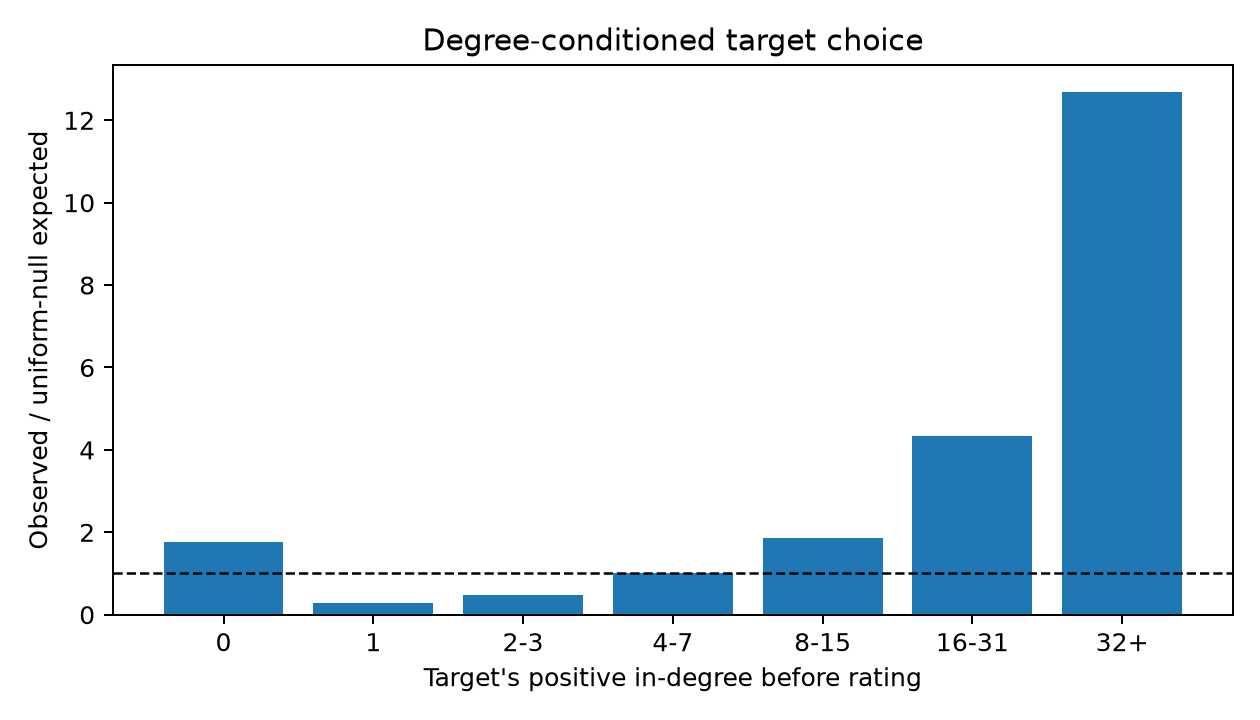

,year,prior_positive_in_degree,observed_target_events,uniform_null_expected_events,observed_over_expected
13,2011,32+,720,63.739,11.296
20,2012,32+,2107,162.001,13.006
27,2013,32+,2942,243.703,12.072
34,2014,32+,1147,86.252,13.298
41,2015,32+,419,22.636,18.510


In [3]:
display(choice.round(3))
display(Image(filename=str(OUT / 'target_choice_ratio.png')))
display(by_year[by_year.prior_positive_in_degree == '32+'].query('2011 <= year <= 2015').round(3))

## 4. Sensitivity and interpretation

The year-end concentration is recomputed with ratings of at least +5. This threshold is a sensitivity choice, not a new definition of true trust. The strongest conclusion supported here is that incoming positive ratings became more concentrated among observed users and that high-prior-degree users were overrepresented relative to a uniform eligible-target benchmark. The dataset lacks verified transactions and unobserved nonrating platform users. Because there are no repeated directed pairs, it also cannot show how a user's rating of the same person changed.

In [4]:
display(strong.round(4))
print('Top 1% incoming share, 2011 to 2015:')
print('All positive:', round(annual.iloc[0].top_1_percent_incoming_share, 3), 'to', round(annual.iloc[-1].top_1_percent_incoming_share, 3))
print('Rating >=5:', round(strong.iloc[0].top_1_percent_incoming_share, 3), 'to', round(strong.iloc[-1].top_1_percent_incoming_share, 3))

,rating_threshold,year_end,active_positive_users,cumulative_positive_ratings,top_1_percent_incoming_share,incoming_degree_gini,top_group_size
0,5,2011,443,643,0.1633,0.5502,5
1,5,2012,850,1429,0.1659,0.6216,9
2,5,2013,1398,2451,0.1877,0.6614,14
3,5,2014,1551,2793,0.1926,0.6660,16
4,5,2015,1585,2885,0.1931,0.6694,16


Top 1% incoming share, 2011 to 2015:
All positive: 0.155 to 0.235
Rating >=5: 0.163 to 0.193


## References

- [SNAP Bitcoin OTC dataset and original dataset paper](https://snap.stanford.edu/data/soc-sign-bitcoinotc.html)
- [Barabási and Albert (1999), emergence of scaling](https://doi.org/10.1126/science.286.5439.509)
- [Jeong, Néda, and Barabási (2003), measuring preferential attachment](https://doi.org/10.1209/epl/i2003-00166-9)

The analysis borrows the idea of measuring new links against prior degree, but its null model and observational limits are stated explicitly above.